# Ablation Comparison
This script is intended as a somewhat quantitative analysis of the results of ablating the MultiVelo model inputs. It primarily uses the benchmarks that the ArchVelo paper uses. This script works in conjunction with the ablations/rankings carried out in the `mv_gene_ranking.ipynb` notebooks.

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings("ignore")
from scipy.cluster.hierarchy import cut_tree, linkage
from sklearn.metrics import silhouette_score as ss
import scvelo as scv
from scipy.stats import wilcoxon
from sklearn.neighbors import NearestNeighbors
import multivelo as mv
from sklearn.metrics.pairwise import cosine_similarity

## Data preparation

In [2]:
pal = ['#E4504F', '#566CB3', '#ACACAC', '#F2A138', "#B138F2", "#38F2A1"]

In [3]:
python_data_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\data"

scv.settings.verbosity = 3
scv.settings.presenter_view = True
scv.set_figure_params('scvelo')
scv.settings.figdir = rf"{python_data_dir}\multivelo_comparison"
scv.settings.plot_prefix = ""
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)
np.set_printoptions(suppress=True)

computing velocity graph (using 1/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:14) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing terminal states
    identified 0 region of root cells and 1 region of end points .
    finished (0:00:01) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)
computing latent time using root_cells as prior
    finished (0:00:02) --> added 
    'latent_time', shared time (adata.obs)
computing velocity embedding
    finished (0:00:02) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


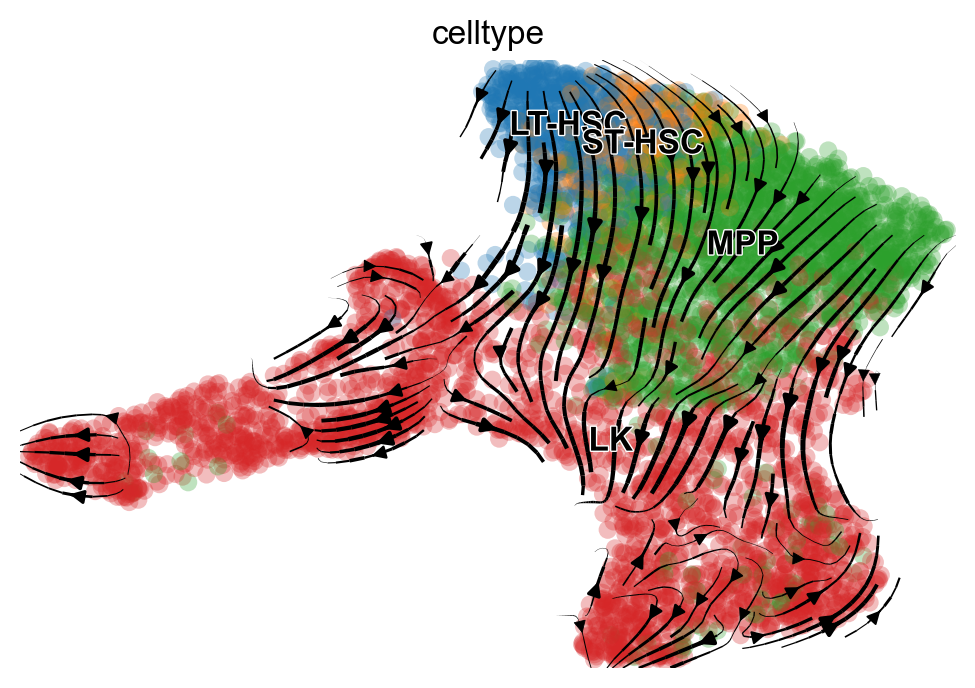

computing velocity graph (using 1/8 cores)


  0%|          | 0/5380 [00:00<?, ?cells/s]

    finished (0:01:55) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:03) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


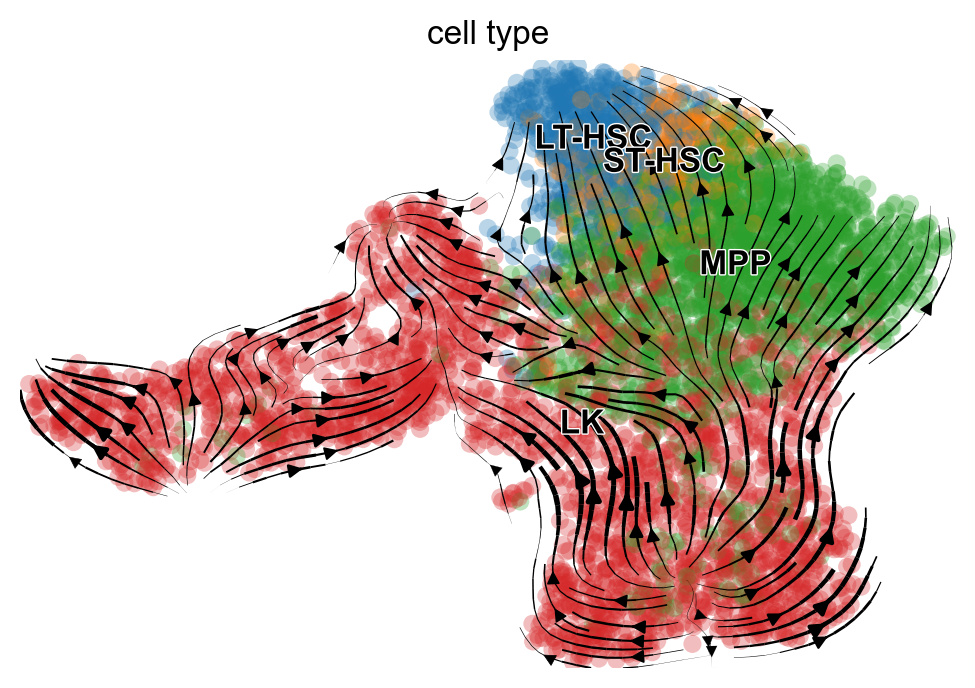

In [4]:
mv_data = sc.read_h5ad(rf"{python_data_dir}\multivelo_results_v3.h5ad")
scv_data = sc.read_h5ad(rf"{python_data_dir}\scvelo_results_full.h5ad")
av_data = sc.read_h5ad(rf"{python_data_dir}\archvelo_final_result_full.h5ad")

# prep MultiVelo data some more
mv.velocity_graph(mv_data)
mv.latent_time(mv_data)
mv.velocity_embedding_stream(mv_data, basis='umap', color='celltype')

# prep scVelo data
scv.tl.velocity_graph(scv_data)
scv.pl.velocity_embedding_stream(scv_data, basis='umap', color="cell_type")

In [5]:
gene_ranking = pd.read_csv(f"{python_data_dir}\mv_gene_ranking.csv", header=0, index_col=0)
mv_sub_data = {}

subsets = [25, 50, 100]

for s in subsets: 
    top_s_genes = gene_ranking[:s].index.values
    mv_sub_data[f"top{s}_sub"] = mv_data[:,top_s_genes].layers["fit_t"].copy()

In [6]:
def set_knn_indices(adata, rep="X_umap", k=50, include_self=True):
    emb = adata.obsm[rep]
    _, idx = NearestNeighbors(n_neighbors=k + (not include_self)).fit(emb).kneighbors(emb)
    if not include_self:
        idx = idx[:, 1:]
    adata.uns.setdefault('neighbors', {})['indices'] = idx
    assert idx.shape == (adata.n_obs, k)

In [7]:
common = (
    av_data.obs_names
    .intersection(mv_data.obs_names)
    .intersection(scv_data.obs_names)
)

mv_idx = mv_data.obs_names.get_indexer(common)

av_data = av_data[common].copy()
mv_data = mv_data[common].copy()
scv_data = scv_data[common].copy()

for k, v in mv_sub_data.items():
    mv_sub_data[k] = v[mv_idx, :].copy()

for d in (av_data, mv_data, scv_data):
    set_knn_indices(d)

## Extract latent time information and compute correlations

In [10]:
sub = "full"
times = {}

subs = ["full", "top25_sub", "top50_sub", "top100_sub"]
times['MultiVelo'] = {}

mv_sub_data["full"] = mv_data.layers['fit_t']

for sub in subs:
    times['MultiVelo'][sub] = mv_sub_data[sub]
    times['MultiVelo'][sub] = pd.DataFrame(times['MultiVelo'][sub])


mv_genes = mv_data.var_names.values
intersect_scv = scv_data.var_names.intersection(mv_genes)
times["scVelo"] = scv_data[:, intersect_scv].layers['fit_t']
times["scVelo"] = pd.DataFrame(times["scVelo"])

intersect_av = av_data.var_names.intersection(mv_genes)
times["ArchVelo"] = av_data[:, intersect_av].layers['fit_t']
times["ArchVelo"] = pd.DataFrame(times["ArchVelo"])

In [13]:
corrs = {}
method_multi = "MultiVelo"
method_single = "scVelo"

corrs[method_multi] = {}

for sub in subs:
    corrs[method_multi][sub] = times[method_multi][sub].corr(method = 'spearman').fillna(0)

corrs[method_single] = times[method_single].corr(method = 'spearman').fillna(0)
corrs["ArchVelo"] = times["ArchVelo"].corr(method = 'spearman').fillna(0)

## Silhouette scores
Compute silhouette scores by cutting the dendrogram at different depths. The rationale here is that models with a consistent latent time should have a clear block structure in the correlation matrix.

In [14]:
linestyles = dict(zip([method_multi, method_single, "ArchVelo"], ['solid']*4))

sil_scores = {}
clusts = {}

sil_scores[method_multi] = {}
clusts[method_multi] = {}
ls = linestyles[method_multi]

for sub in subs:
    sil_scores[method_multi][sub] = {}
    clusts[method_multi][sub] = {}

    for i in range(2, 20):
        clusts[method_multi][sub][i] = cut_tree(linkage(corrs[method_multi][sub], method='average', metric='euclidean'), n_clusters = i)
        sil_scores[method_multi][sub][i] = ss(corrs[method_multi][sub], clusts[method_multi][sub][i])
    sil_scores[method_multi][sub] = pd.Series(sil_scores[method_multi][sub])

In [15]:
sil_scores[method_single] = {}
clusts[method_single] = {}

for i in range(2,20):
    clusts[method_single][i] = cut_tree(linkage(corrs[method_single], method='average', metric='euclidean'), n_clusters = i)
    sil_scores[method_single][i] = ss(corrs[method_single], clusts[method_single][i])

sil_scores[method_single] = pd.Series(sil_scores[method_single])

In [16]:
sil_scores["ArchVelo"] = {}
clusts["ArchVelo"] = {}
ls = linestyles["ArchVelo"]

sil_scores["ArchVelo"] = {}
clusts["ArchVelo"] = {}

for i in range(2, 20):
    clusts["ArchVelo"][i] = cut_tree(linkage(corrs["ArchVelo"], method='average', metric='euclidean'), n_clusters = i)
    sil_scores["ArchVelo"][i] = ss(corrs["ArchVelo"], clusts["ArchVelo"][i])
sil_scores["ArchVelo"] = pd.Series(sil_scores["ArchVelo"])

Comparisons are one-to-one, so first scVelo against MultiVelo...

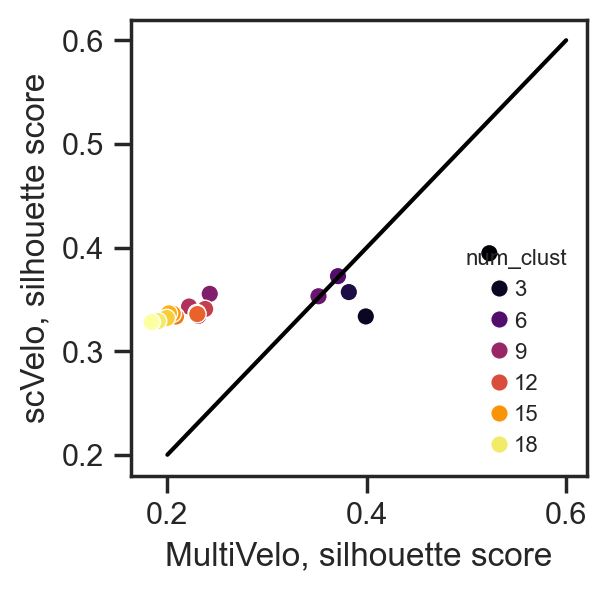

In [17]:
sns.set(style = 'ticks', font_scale = 1.)
fig, ax = plt.subplots(1,1, figsize = (4,3))
ax.set_box_aspect(1)

xx = pd.Series(sil_scores['MultiVelo']["full"])
yy = pd.Series(sil_scores['scVelo'])
g = sns.scatterplot(x = xx, 
            y = yy,
           ax = ax, s = 40,
               hue = range(2,20),
                   palette = 'inferno')

plt.legend(frameon = False, title = 'num_clust', 
           fontsize = 8, title_fontsize = 8, loc = 'lower right')
plt.ylabel('scVelo, silhouette score')
plt.xlabel('MultiVelo, silhouette score')
plt.plot([0.2, 0.6], [0.2, 0.6], c = 'black')
plt.show()

... and then MultiVelo against ArchVelo.

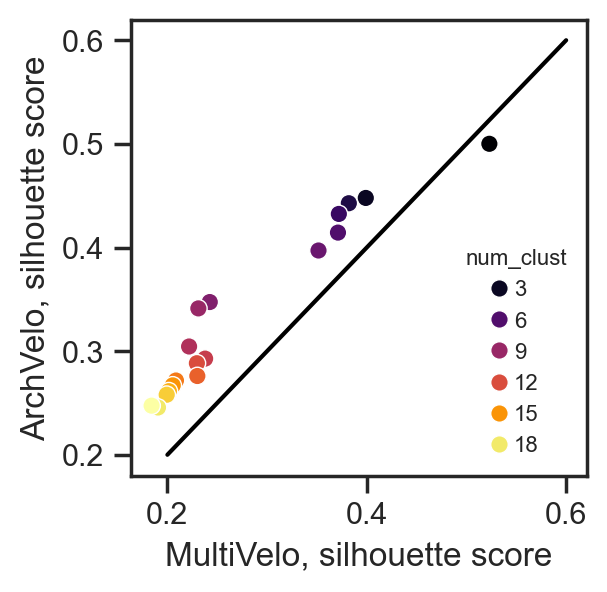

In [18]:
sns.set(style = 'ticks', font_scale = 1.)
fig, ax = plt.subplots(1,1, figsize = (4,3))
ax.set_box_aspect(1)

xx = pd.Series(sil_scores['MultiVelo']["full"])
yy = pd.Series(sil_scores['ArchVelo'])
g = sns.scatterplot(x = xx, 
            y = yy,
           ax = ax, s = 40,
               hue = range(2,20),
                   palette = 'inferno')

plt.legend(frameon = False, title = 'num_clust', 
           fontsize = 8, title_fontsize = 8, loc = 'lower right')
plt.ylabel('ArchVelo, silhouette score')
plt.xlabel('MultiVelo, silhouette score')
plt.plot([0.2, 0.6], [0.2, 0.6], c = 'black')
plt.show()

In [99]:
# sns.set(style='white', font_scale=1.)
# for name, res in [(method_multi, corrs[method_multi][sub]),
#                   (method_single, corrs[method_single])]:
#     g = sns.clustermap(res, method='average', metric='euclidean',
#                        cmap='coolwarm', center=0,
#                        xticklabels=0, yticklabels=0, cbar_pos=None)
#     g.ax_heatmap.set_xlabel('Genes', fontsize=30)
#     g.ax_heatmap.set_ylabel('Genes', fontsize=30)

#     cax = g.fig.add_axes([0.42, 0.9, 0.3, 0.02])
#     sm = plt.cm.ScalarMappable(cmap='coolwarm',
#                                norm=plt.Normalize(res.values.min(), res.values.max()))
#     cb = g.fig.colorbar(sm, cax=cax, orientation='horizontal')
#     cb.set_label(r'$\rho$, latent time', fontsize=30)
#     cax.xaxis.set_label_position('top')
#     cax.xaxis.set_ticks_position('top')
#     plt.suptitle(name, fontsize=40, y=1.05, x=0.57)

## Comparison of model likelihoods
Pairwise comparison of u-s-likelihoods per gene

In [19]:
inter = intersect_scv.values.tolist()
assert inter == mv_data.var_names.values.tolist() # 

AssertionError: 

WilcoxonResult(statistic=1.0, pvalue=1.52587890625e-05)


Text(0, 0.5, 'scVelo, u-s loglikelihood')

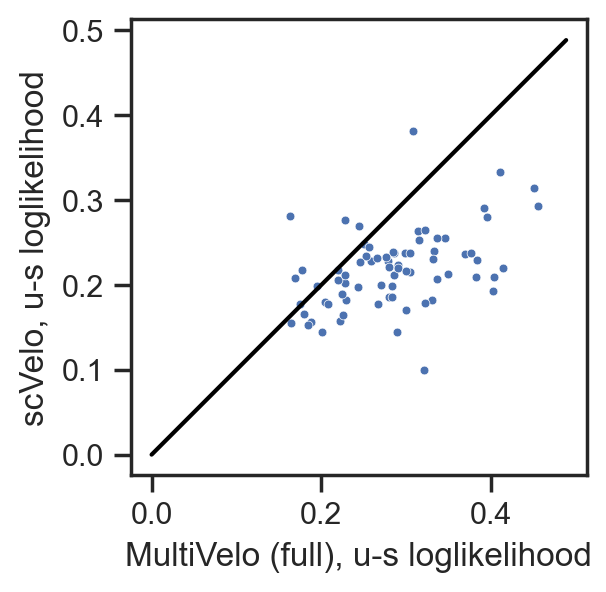

In [20]:
print(wilcoxon(x=yy.dropna(), y=xx.loc[yy.dropna().index],
               zero_method='wilcox', correction=False))

liks = {
    # method_multi:  (mv_data[:, intersect_scv].var['fit_likelihood']
    #                     / mv_data[:, intersect_scv].var['fit_likelihood_c']),
    method_single: scv_data[:, intersect_scv].var['fit_likelihood'],
}

for sub in subs: 
    top_s_genes = gene_ranking[:s].index.values
    liks[f"mv_{sub}"] = (mv_data[:,top_s_genes].var["fit_likelihood"] / mv_data[:,top_s_genes].var["fit_likelihood_c"])

xx_l = np.log1p(liks["mv_full"])
yy_l = np.log1p(liks[method_single])

sns.set(style='ticks', font_scale=1.)
fig, ax = plt.subplots(1, 1, figsize=(4, 3))
ax.set_box_aspect(1)
sns.scatterplot(x=xx_l, y=yy_l, ax=ax, s=10)
lim = max(xx_l.max(), yy_l.max())
plt.plot([0, lim], [0, lim], c='black')
plt.xlabel('MultiVelo (full), u-s loglikelihood')
plt.ylabel('scVelo, u-s loglikelihood')

# print(wilcoxon(x=yy_l.dropna(), y=xx_l.loc[yy_l.dropna().index],
#                zero_method='wilcox', correction=False))

## Merging of likelihood and silhouette score
The two metrics are merged into a single plot with points higher further right indicating a better model

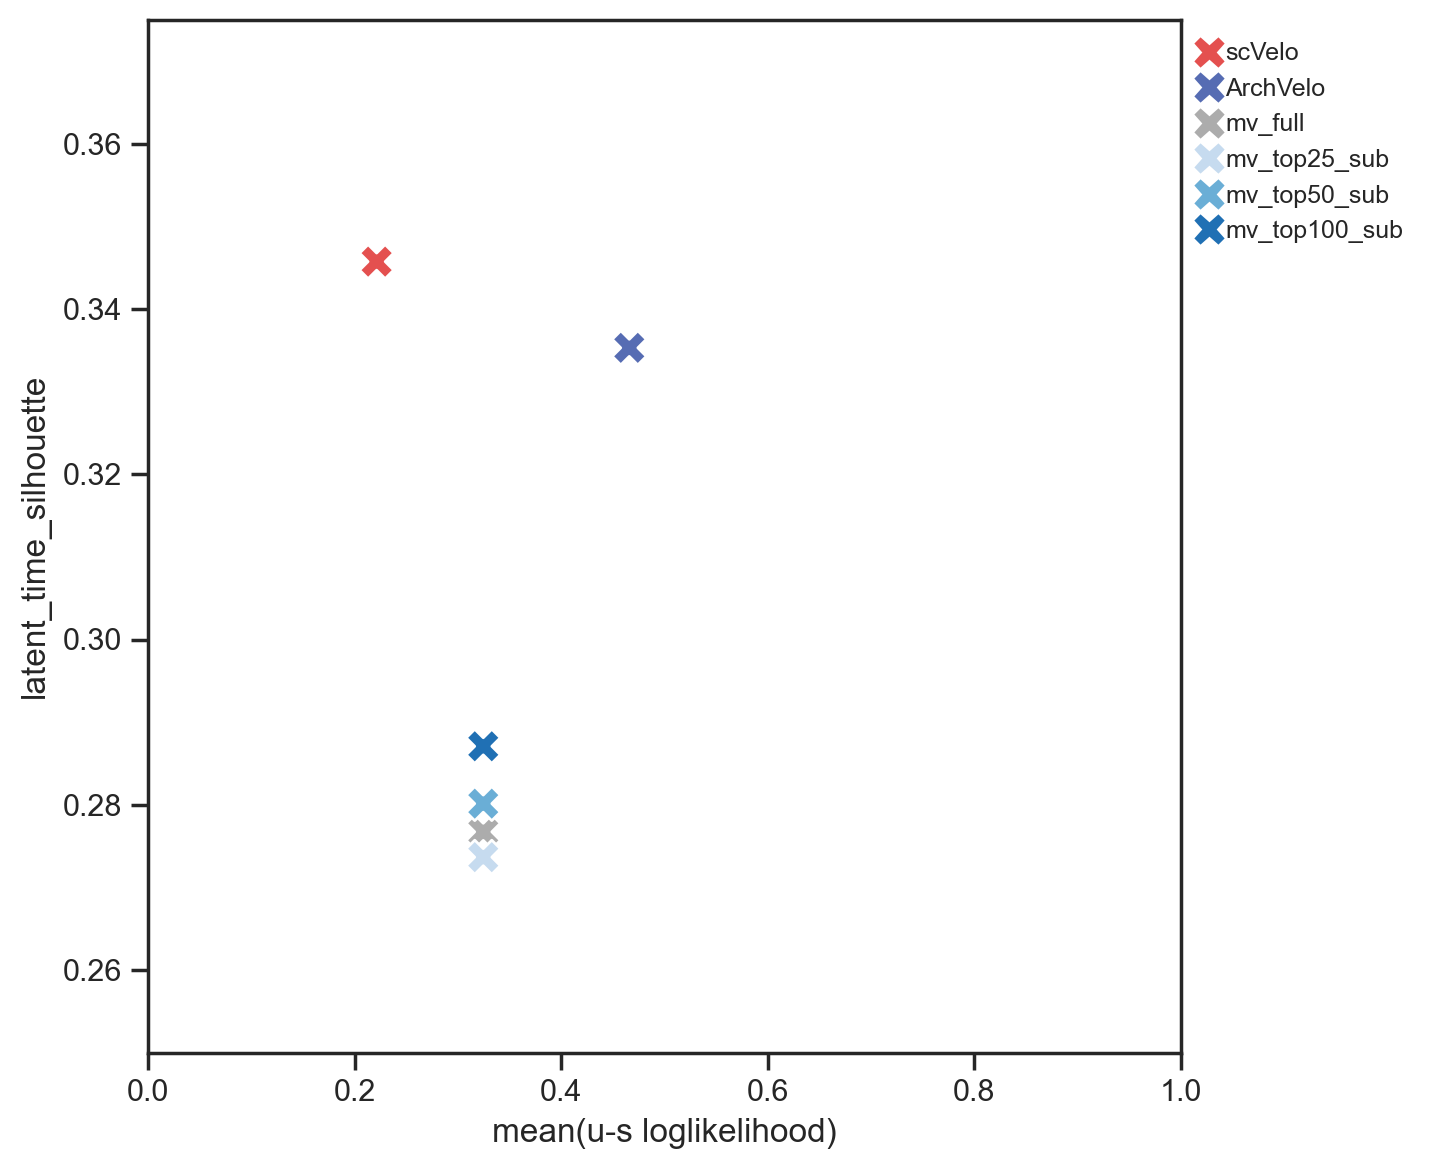

In [25]:
method_arch = 'ArchVelo'
lik_arch = av_data.var["fit_likelihood"]
lik_arch = lik_arch.reindex(intersect_scv)

plot_palette = {method_single: pal[0], method_arch: pal[1]}

overview_dict = {
    'method': [method_single, method_arch],
    'latent_time_silhouette': [sil_scores[method_single].mean(),
                               sil_scores[method_arch].mean()],
    'mean(u-s loglikelihood)': [yy_l.mean(),
                                np.log1p(lik_arch).mean()],
}

for i, sub in enumerate(subs): 
    overview_dict["method"].append(f"mv_{sub}")
    overview_dict["latent_time_silhouette"].append(sil_scores["MultiVelo"][sub].mean())
    overview_dict["mean(u-s loglikelihood)"].append(liks[f"mv_{sub}"].mean())
    plot_palette[f"mv_{sub}"] = pal[i+2]

bench = pd.DataFrame(overview_dict)

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.set_box_aspect(1)
sns.scatterplot(data=bench, x='mean(u-s loglikelihood)', y='latent_time_silhouette',
                hue='method',
                palette=plot_palette, 
                s=150, marker='X', ax=ax)
ax.set_ylim(0.25, 0.375)
ax.set_xlim(0, 1)
plt.legend(fontsize=9, frameon=False, bbox_to_anchor=(1, 1), loc='upper left')
plt.tight_layout()

## CBDir
To avoid having to load a different environment that can handle ArchVelo, we can simply directly import the two functions needed

In [8]:
def keep_type(adata, nodes, target, k_cluster):
    return nodes[adata.obs[k_cluster][nodes].values == target]


def cross_boundary_correctness(
    adata, 
    k_cluster, 
    k_velocity, 
    cluster_edges, 
    return_raw=False, 
    x_emb="X_umap"
):
    scores = {}
    all_scores = {}
    
    if x_emb == "X_umap":
        v_emb = adata.obsm['{}_umap'.format(k_velocity)]
    else:
        v_emb = adata.obsm[[key for key in adata.obsm if key.startswith(k_velocity)][0]]
        
    x_emb = adata.obsm[x_emb]
    
    for u, v in cluster_edges:
        sel = adata.obs[k_cluster] == u
        nbs = adata.uns['neighbors']['indices'][sel] # [n * 30]
        
        boundary_nodes = map(lambda nodes:keep_type(adata, nodes, v, k_cluster), nbs)
        x_points = x_emb[sel]
        x_velocities = v_emb[sel]
        
        type_score = []
        for x_pos, x_vel, nodes in zip(x_points, x_velocities, boundary_nodes):
            if len(nodes) == 0: continue

            position_dif = x_emb[nodes] - x_pos
            dir_scores = cosine_similarity(position_dif, x_vel.reshape(1,-1)).flatten()
            type_score.append(np.mean(dir_scores))
        
        scores[(u, v)] = np.mean(type_score)
        all_scores[(u, v)] = type_score
        
    if return_raw:
        return all_scores 
    
    return scores, np.mean([sc for sc in scores.values()])

This analysis critically reveals that while scVelo and ArchVelo outperform MultiVelo across some of the other metrics, they do not recpaitulate the correct biological directions?

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:35) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:03) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


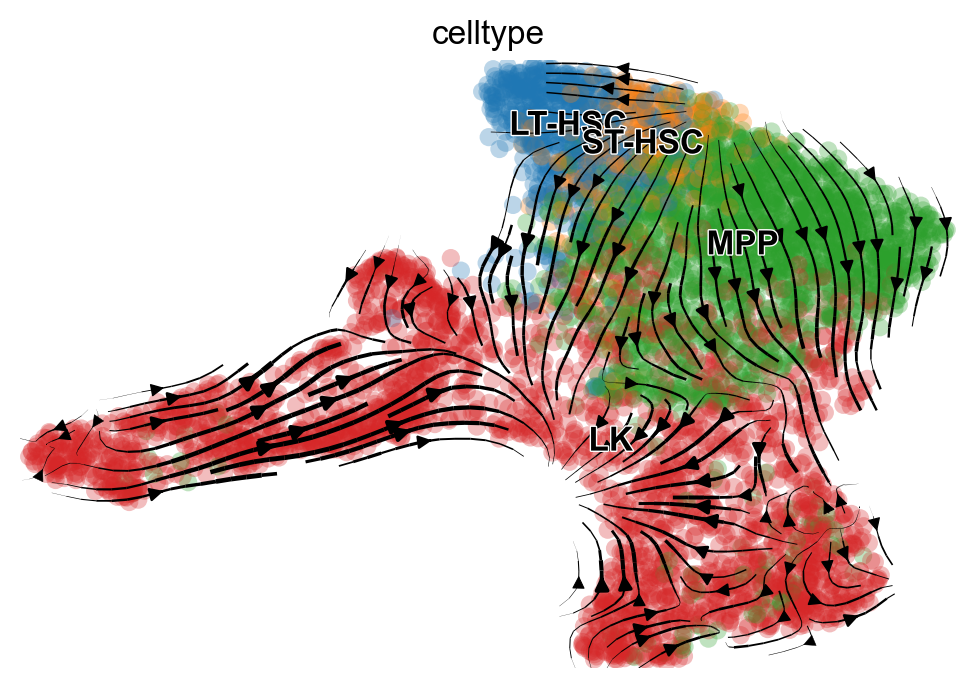

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:18) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:03) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


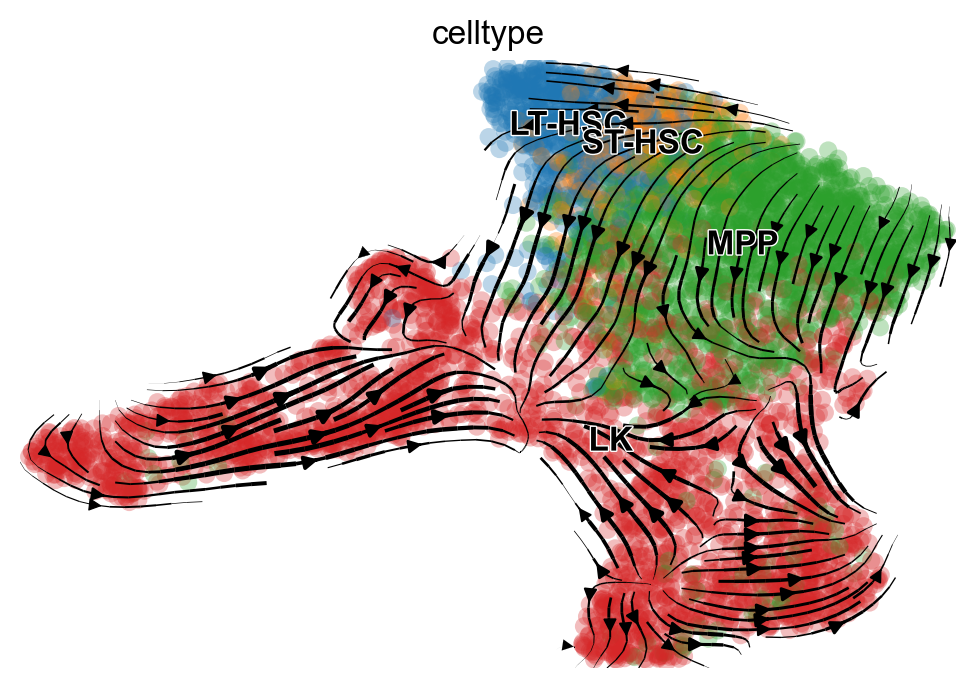

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:18) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:04) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


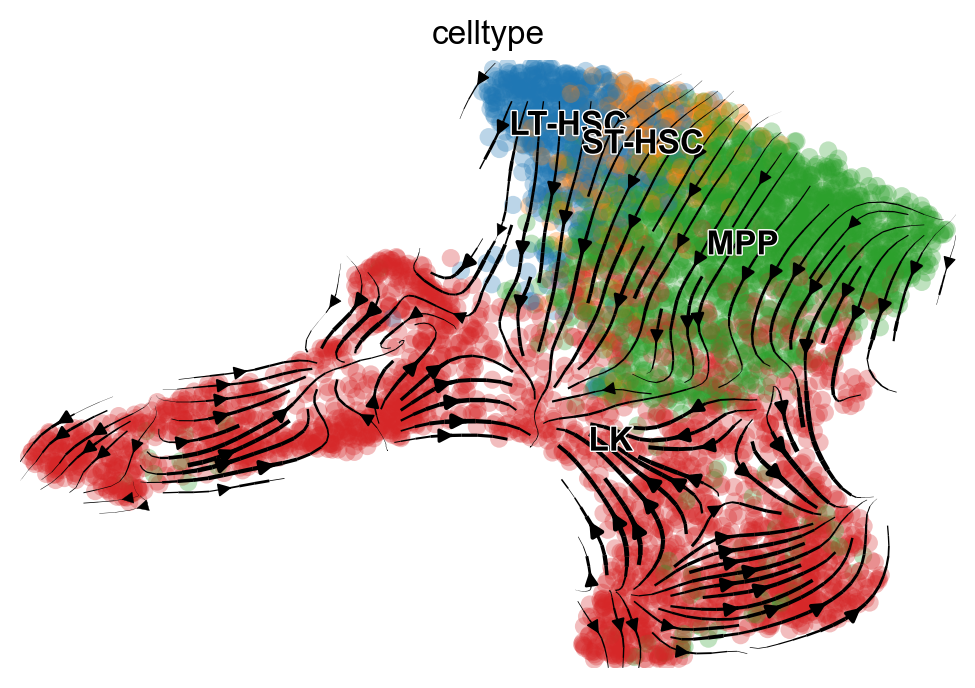

In [11]:
celltype_name = 'cell_type'
edges = [('LT-HSC', 'ST-HSC'), ('ST-HSC', 'MPP'), ("MPP", "LK")]

runs = {
    'ArchVelo': (av_data, 'velo_s_norm'),
    'scVelo': (scv_data, 'velocity'),
}

for i, sub in enumerate(subs):
    if i == 0: 
        runs[f'mv_{sub}'] = (mv_data, 'velo_s_norm')
    else: 
        s = subsets[i-1]
        top_s_genes = gene_ranking[:s].index.values
        sub_data = mv_data[:, top_s_genes]

        mv.velocity_graph(sub_data, n_jobs=8)
        mv.velocity_embedding_stream(sub_data, basis='umap', color='celltype')
        
        runs[f'mv_{sub}'] = (sub_data, 'velo_s_norm')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


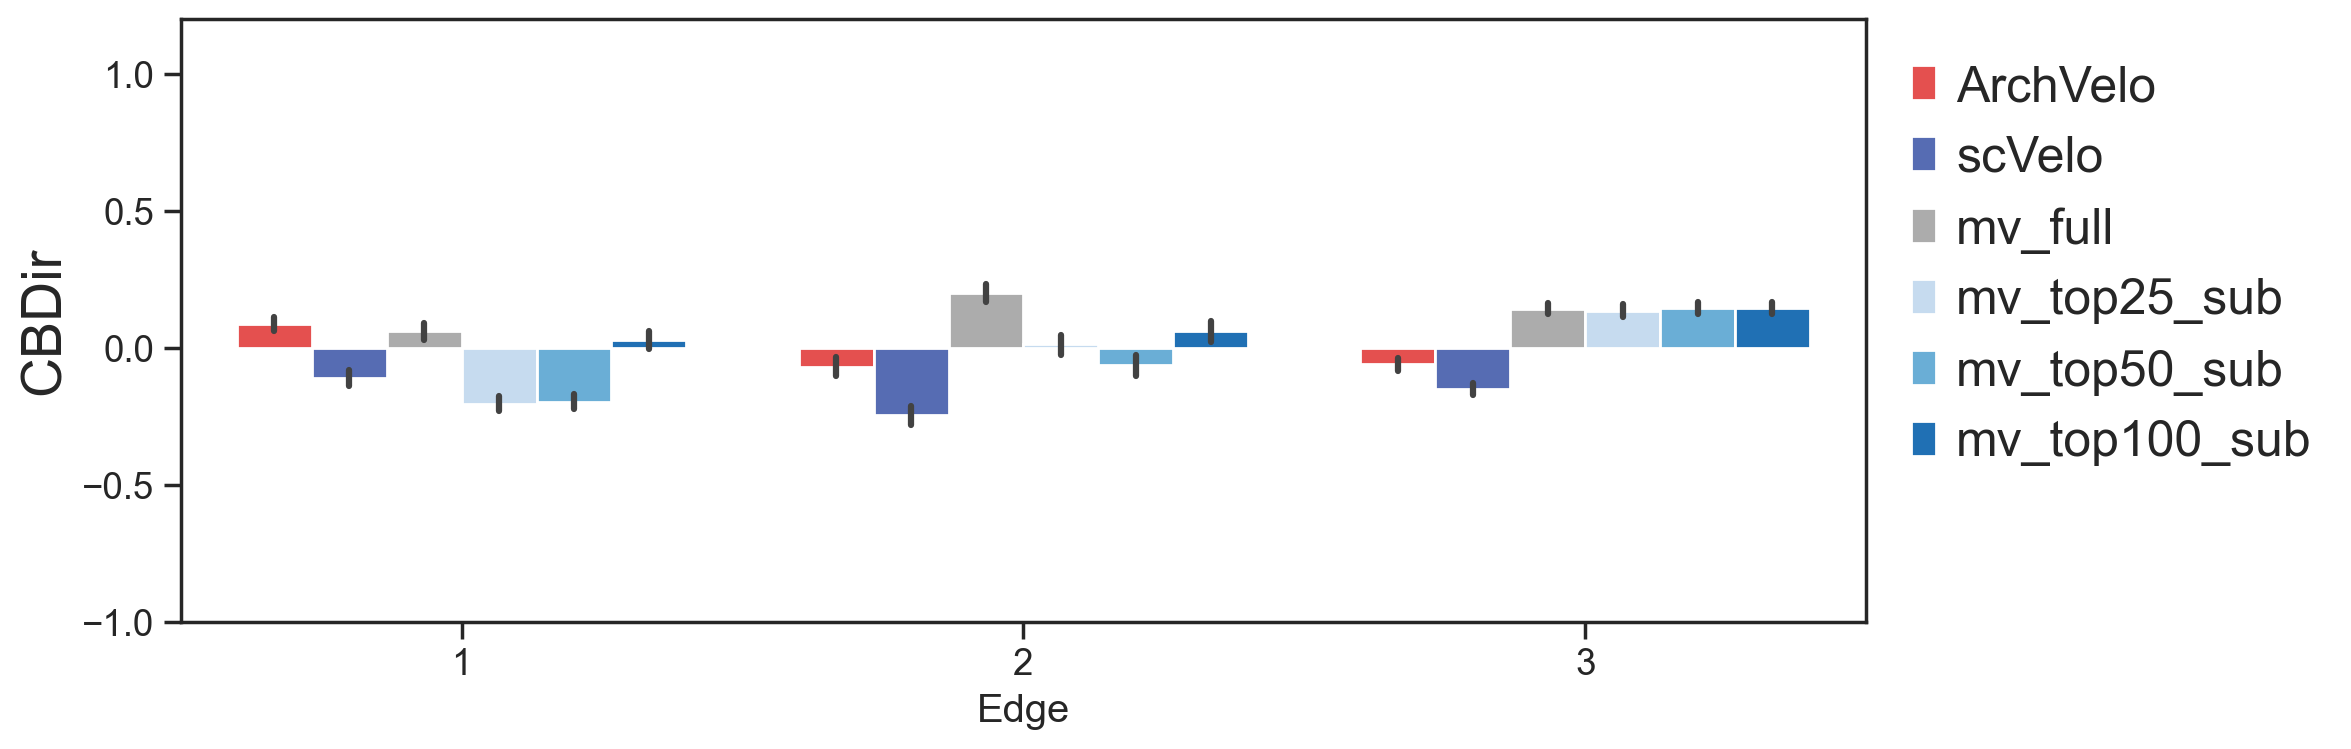

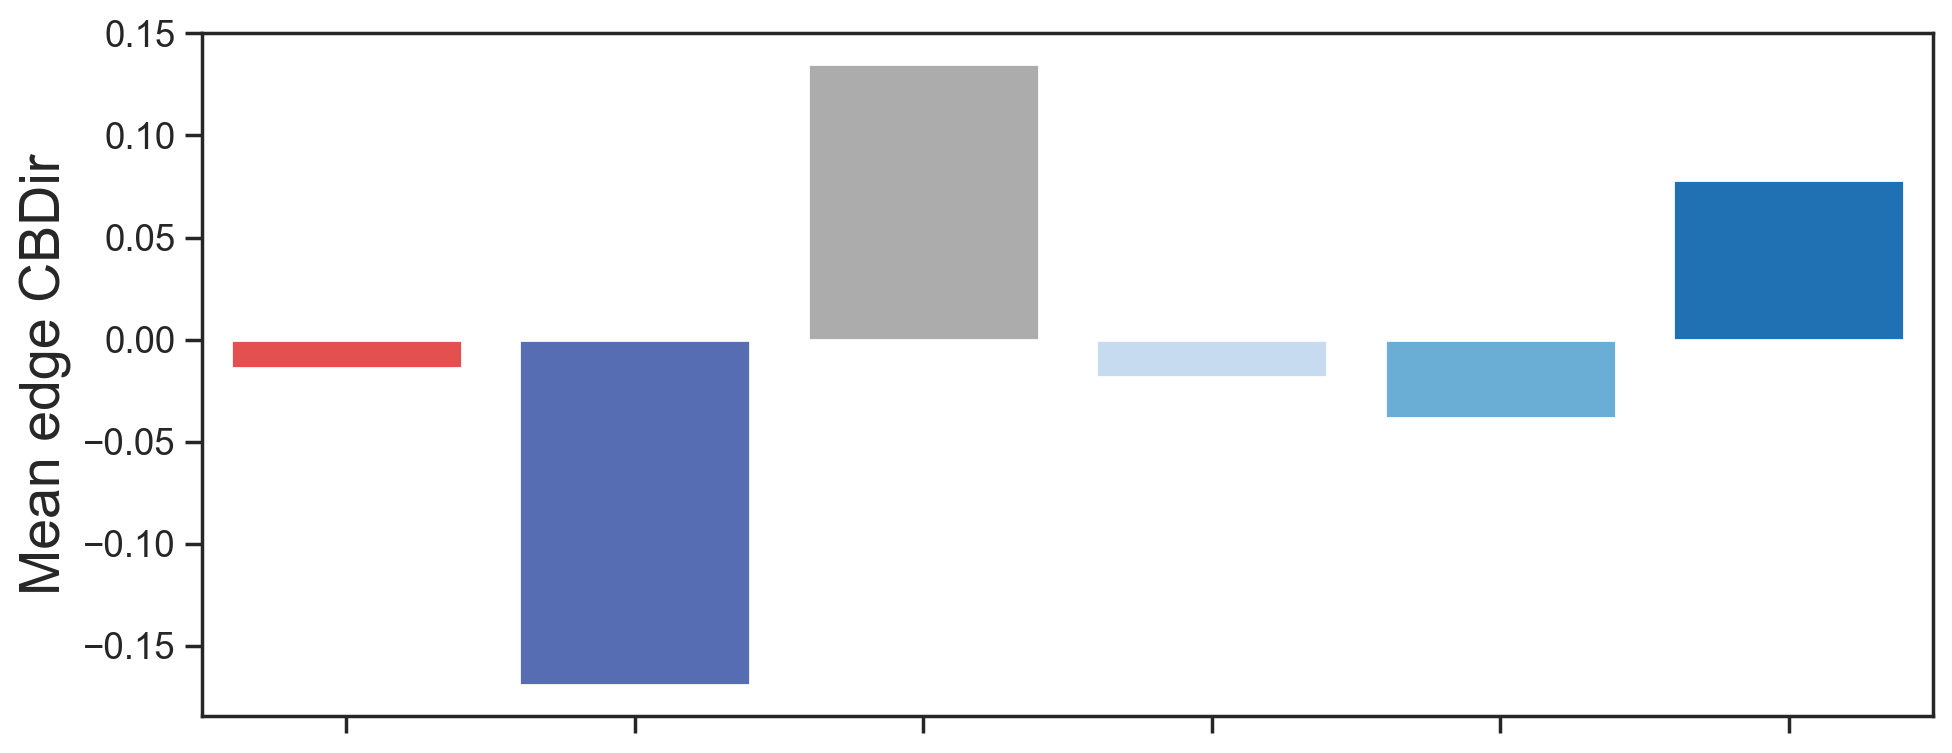

In [12]:
CBCs = {}
for name, (dat, vk) in runs.items():
    if name.startswith("mv"):  # MultiVelo uses a different cell type label than the rest
        celltype_name = "celltype"
    else:
        celltype_name = "cell_type"
    CBCs[name] = cross_boundary_correctness(dat, celltype_name, vk, edges, x_emb='X_umap', return_raw=True)

hue_order = list(runs)
pal = ['#E4504F', '#566CB3', '#ACACAC'] + list(sns.color_palette('Blues', len(runs) - 3))

all_CBCs = pd.concat(
    [pd.concat([pd.Series(CBCs[m][k]) for k in CBCs[m]], keys=[str(k[0]) for k in CBCs[m]]) for m in CBCs],
    keys=CBCs.keys()).reset_index()
all_CBCs.columns = ['Method', 'Edge', 'Cell', 'CBD']

sns.set(style='ticks', font_scale=1.2)
plt.figure(figsize=(12, 4))
sns.barplot(data=all_CBCs, x='Edge', y='CBD', hue='Method', hue_order=hue_order, palette=pal, saturation=1)
plt.xticks(range(len(edges)), [str(i) for i in range(1, len(edges) + 1)])
plt.ylabel('CBDir', fontsize=20)
plt.xlabel('Edge')
plt.legend(frameon=False, fontsize=18, bbox_to_anchor=(1, 1))
plt.ylim(-1, 1.2)
plt.tight_layout()

edge_means = all_CBCs.groupby(['Method', 'Edge'])['CBD'].mean().reset_index()

plt.figure(figsize=(10, 4))
g = sns.barplot(data=edge_means, x='Method', y='CBD', hue='Method', order=hue_order, hue_order=hue_order,
                palette=pal, errorbar=None, saturation=1)
plt.ylabel('Mean edge CBDir', fontsize=20)
g.set(xticklabels=[], xlabel=None)
plt.legend(frameon=False, fontsize=20, bbox_to_anchor=(1, 1))
plt.tight_layout()